In [1]:
import numpy as np
import pandas as pd

#전처리(인코딩)
from sklearn.preprocessing import LabelEncoder

#전처리(스케일링)
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import MaxAbsScaler

#데이터 나누기
from sklearn.model_selection import train_test_split

#학습모델
from sklearn.ensemble import RandomForestRegressor

#평가
from sklearn.metrics import root_mean_squared_log_error

In [26]:
train = pd.read_csv('car_train.csv')
test = pd.read_csv('car_test.csv')

print('train :', train.shape)
print('test :', test.shape)

train : (6732, 17)
test : (5772, 16)


In [27]:
set(train) - set(test)

{'Price'}

<Axes: >

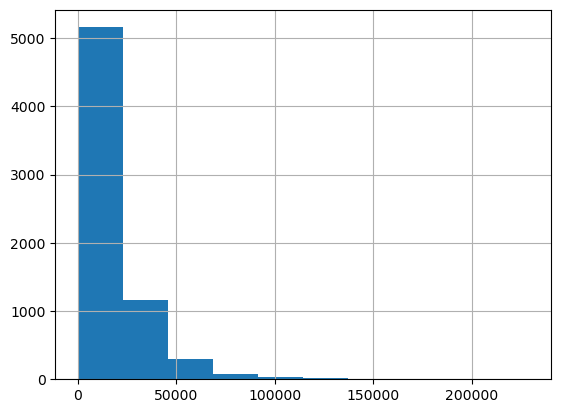

In [28]:
target = train.pop('Price')
target.hist()

In [29]:
train.head(10)

,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,603,LEXUS,RX 450,2015,Jeep,Yes,Hybrid,3.5,143619 km,6.0,Automatic,4x4,04-May,Left wheel,Black,12
1,640,SSANGYONG,REXTON,2013,Jeep,Yes,Diesel,2,111307 km,4.0,Automatic,Front,04-May,Left wheel,White,4
2,1493,MERCEDES-BENZ,GLE 350,2016,Jeep,Yes,Petrol,3.5,91493 km,6.0,Automatic,Rear,04-May,Left wheel,Black,0
3,475,FIAT,500,2012,Sedan,Yes,Petrol,1.4,88000 km,4.0,Tiptronic,Front,02-Mar,Left wheel,Black,6
4,639,CHEVROLET,Orlando,2014,Jeep,Yes,Diesel,2,177103 km,4.0,Automatic,Front,04-May,Left wheel,White,4
5,-,FORD,Transit,2008,Microbus,No,Diesel,2.4 Turbo,214000 km,4.0,Manual,Rear,04-May,Left wheel,Orange,2
6,-,JAGUAR,XJ,1999,Sedan,Yes,Petrol,4,1000 km,8.0,Tiptronic,4x4,04-May,Left wheel,Green,7
7,891,BMW,330,2016,Sedan,Yes,Petrol,2.0 Turbo,51000 km,4.0,Tiptronic,Rear,04-May,Left wheel,Blue,10
8,640,SUZUKI,SX4,2013,Sedan,Yes,Petrol,2,193504 km,4.0,Automatic,Front,04-May,Left wheel,Red,0
9,761,CHEVROLET,Lacetti,2010,Sedan,Yes,Petrol,1.8,153966 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


In [30]:
train.isnull().sum()

Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [33]:
train['Turbo'] = train['Engine volume'].str.contains('Turbo').astype(int)
train['Engine volume'] = train['Engine volume'].str.replace('Turbo', '').astype(float)

test['Turbo'] = test['Engine volume'].str.contains('Turbo').astype(int)
test['Engine volume'] = test['Engine volume'].str.replace('Turbo', '').astype(float)

In [34]:
train['Mileage'] = train['Mileage'].str.split().str[0].astype(int)
test['Mileage'] = test['Mileage'].str.split().str[0].astype(int)

In [36]:
obj_cols = train.select_dtypes(include='O').columns
obj_cols

Index(['Levy', 'Manufacturer', 'Model', 'Category', 'Leather interior',
       'Fuel type', 'Gear box type', 'Drive wheels', 'Doors', 'Wheel',
       'Color'],
      dtype='object')

In [37]:
for col in obj_cols:
    is_same = False
    if set(train[col]) == set(test[col]):
        is_same=True
    print(col,":",is_same)

Levy : False
Manufacturer : False
Model : False
Category : True
Leather interior : True
Fuel type : False
Gear box type : True
Drive wheels : True
Doors : True
Wheel : True
Color : True


In [38]:
data = pd.concat([train, test])

for col in obj_cols:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])

In [39]:
train = data[:len(train)].copy()
test = data[len(train):].copy()

In [40]:
x_train,x_val,y_train,y_val = train_test_split(
    train,
    target,
    test_size=0.2,
    random_state=0,
)

In [41]:
model = RandomForestRegressor(n_estimators=200, random_state=0)
model.fit(x_train,y_train)

pred = model.predict(x_val)
pred

array([25116.79 , 16440.275, 10785.695, ...,  1269.64 , 48727.755,
       23457.735])

In [42]:
rmsle = root_mean_squared_log_error(y_val,pred)
print("RMSLE :", rmsle)

RMSLE : 1.082016203127291


In [43]:
pred = model.predict(test)

In [44]:
submit = pd.DataFrame({'pred' : pred})
submit.to_csv('car_result.csv', index=False)
submit.head()

,pred
0,39999.245
1,10820.880
2,16399.925
3,69795.375
4,47603.045
